# DATA QUALITY ASSESSMENT, TARGET ANALYSIS, & EDA — DATASET 2: ONE ACRE FUND
## Pemodelan Prediksi Hasil Panen Jagung untuk Mendukung Perencanaan Produksi Ayam Petelur di Komunitas ASA Indonesia

---

### Identitas Notebook & Penelitian
- **Peneliti:** Mahasiswa Sarjana Terapan Sistem Informasi Bisnis (SIB), Politeknik Negeri Malang
- **Dosen Pembimbing:** Pak Habibie Ed Dien
- **Dataset:** Dataset 2 — One Acre Fund MEL Maize Survey Data (2016–2022)
- **File Sumber:** `02_Raw_Data/Dataset_02_One_Acre_Fund/One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv`
- **Fokus Notebook 2:** *Data Quality Audit, Target Variable Assessment, Exploratory Data Analysis, Feature Relevance & Leakage, Contextual Relevance (Sumenep vs Afrika Sub-Sahara), & Research Implications*
- **Aturan Isolasi Data:** Notebook ini menganalisis **Dataset 2 secara mandiri**. Tidak ada pencampuran baris, variabel, atau kesimpulan dari Dataset 1 (`Smart_Farming_Crop_Yield_2024 (2).csv`). Dataset mentah dipertahankan tanpa modifikasi (*read-only*).

---

## 1. Tujuan Analisis Notebook 2

Pada notebook kedua ini, dilakukan evaluasi kualitas data secara mendalam dan eksplorasi analitis untuk:
1. Menilai kualitas teknis data (*missing values, duplicates, zero-values, outliers, anomaly detection, low-variance*).
2. Mengevaluasi kelayakan target regresi `yield_kg_ha` (distribusi, skewness, kurtosis, zero yield observations).
3. Melakukan visualisasi bivariat dan multivariat hubungan faktor lingkungan, tanah, agronomi, dan varietas terhadap yield.
4. Menganalisis relevansi fitur dengan memisahkan secara ketat fitur **Pre-Planting**, **In-Season**, dan **Post-Harvest (Risiko Data Leakage)**.
5. Menguji relevansi kontekstual empiris Dataset 2 terhadap kondisi riil pertanian jagung di Kabupaten Sumenep, Madura, serta memisahkan kerangka konseptual konversi pakan ayam petelur dari data survei empiris jagung.


---
## 2. Persiapan Lingkungan dan Pemuatan Data


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

DATA_PATH = "../../02_Raw_Data/Dataset_02_One_Acre_Fund/One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv"
OUTPUT_DIR = "output"
FIGURES_DIR = os.path.join(OUTPUT_DIR, "figures")
TABLES_DIR = os.path.join(OUTPUT_DIR, "tables")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Data berhasil dimuat.")
print(f"Bentuk Data: {df.shape[0]:,} baris x {df.shape[1]} kolom")


Data berhasil dimuat.
Bentuk Data: 14,773 baris x 53 kolom


---
## 3. Data Quality Assessment (Pemeriksaan Kualitas Data)

Pemeriksaan kualitas data mencakup 8 dimensi pengujian:
1. Missing values per kolom (jumlah & persentase, serta verifikasi jumlah kolom 100% lengkap).
2. Duplikasi baris (duplikasi absolut vs duplikasi koordinat spasio-temporal).
3. Nilai nol pada variabel numerik (*zero-values*).
4. Nilai tidak wajar atau anomali ekstrem (termasuk audit anomali pada `comp_kg_ha`).
5. Deteksi pencilan (*outliers*) berbasis Interquartile Range (IQR).
6. Inkonsistensi satuan atau format data.
7. Kolom dengan variasi sangat rendah (*low variance / near-zero variance*).
8. Rekomendasi penanganan kualitas data terstruktur.


In [2]:
# 3.1 Analisis Missing Values per Kolom & Verifikasi Kolom Lengkap
missing_series = df.isnull().sum()
missing_pct_series = (missing_series / len(df)) * 100

missing_summary = pd.DataFrame({
    'Tipe Data': df.dtypes.astype(str),
    'Missing Count': missing_series,
    'Missing Pct (%)': missing_pct_series.round(2)
}).sort_values(by='Missing Count', ascending=False)

# Verifikasi Presisi Jumlah Kolom Tanpa Missing Values
cols_zero_null = (missing_summary['Missing Count'] == 0).sum()
pct_zero_null = (cols_zero_null / len(df.columns)) * 100

print(f"Total Kolom dalam Dataset               : {len(df.columns)} kolom")
print(f"Kolom Tanpa Missing Values (100% Lengkap): {cols_zero_null} kolom ({pct_zero_null:.2f}%)")
print(f"Kolom dengan Missing Values (>0%)       : {(missing_summary['Missing Count'] > 0).sum()} kolom ({(100 - pct_zero_null):.2f}%)")
print("\nRincian Kategori Missingness:")
print(f"- Lengkap (0% missing)       : {cols_zero_null} kolom")
print(f"- Missing Rendah (< 5%)      : {((missing_summary['Missing Pct (%)'] > 0) & (missing_summary['Missing Pct (%)'] < 5)).sum()} kolom")
print(f"- Missing Moderat (5 - 30%)  : {((missing_summary['Missing Pct (%)'] >= 5) & (missing_summary['Missing Pct (%)'] <= 30)).sum()} kolom")
print(f"- Missing Tinggi (30 - 50%)  : {((missing_summary['Missing Pct (%)'] > 30) & (missing_summary['Missing Pct (%)'] <= 50)).sum()} kolom")
print(f"- Missing Kritis (> 50%)     : {(missing_summary['Missing Pct (%)'] > 50).sum()} kolom")

missing_summary[missing_summary['Missing Count'] > 0]


Total Kolom dalam Dataset               : 53 kolom
Kolom Tanpa Missing Values (100% Lengkap): 20 kolom (37.74%)
Kolom dengan Missing Values (>0%)       : 33 kolom (62.26%)
Rincian Kategori Missingness:
- Lengkap (0% missing)       : 20 kolom
- Missing Rendah (< 5%)      : 3 kolom
- Missing Moderat (5 - 30%)  : 8 kolom
- Missing Tinggi (30 - 50%)  : 17 kolom
- Missing Kritis (> 50%)     : 5 kolom


,Tipe Data,Missing Count,Missing Pct (%)
manure,object,13887,94.0000
striga,object,12249,82.9100
hyb_type,str,12191,82.5200
hyb_yor,float64,7903,53.5000
comp_kg_ha,float64,7726,52.3000
hyb_tol_rust,object,7191,48.6800
hyb_tol_msv,object,7191,48.6800
hyb_tol_gls,object,7191,48.6800
hyb_tol_ear_rot,object,7191,48.6800
hyb_tol_mln,object,7191,48.6800


In [3]:
# Daftar 20 Kolom Tanpa Missing Values
cols_complete = missing_summary[missing_summary['Missing Count'] == 0].index.tolist()
df_complete_cols = pd.DataFrame({
    'No': range(1, len(cols_complete) + 1),
    'Nama Kolom': cols_complete,
    'Tipe Data': [str(df[c].dtype) for c in cols_complete],
    'Jumlah Non-Null': [df[c].notnull().sum() for c in cols_complete]
})
df_complete_cols


,No,Nama Kolom,Tipe Data,Jumlah Non-Null
0,1,cz,int64,14773
1,2,iso,str,14773
2,3,season,str,14773
3,4,year,int64,14773
4,5,season_prec_2,float64,14773
5,6,season_prec_3,float64,14773
6,7,elev,int64,14773
7,8,twi,float64,14773
8,9,lon,float64,14773
9,10,lat,float64,14773


<ast>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


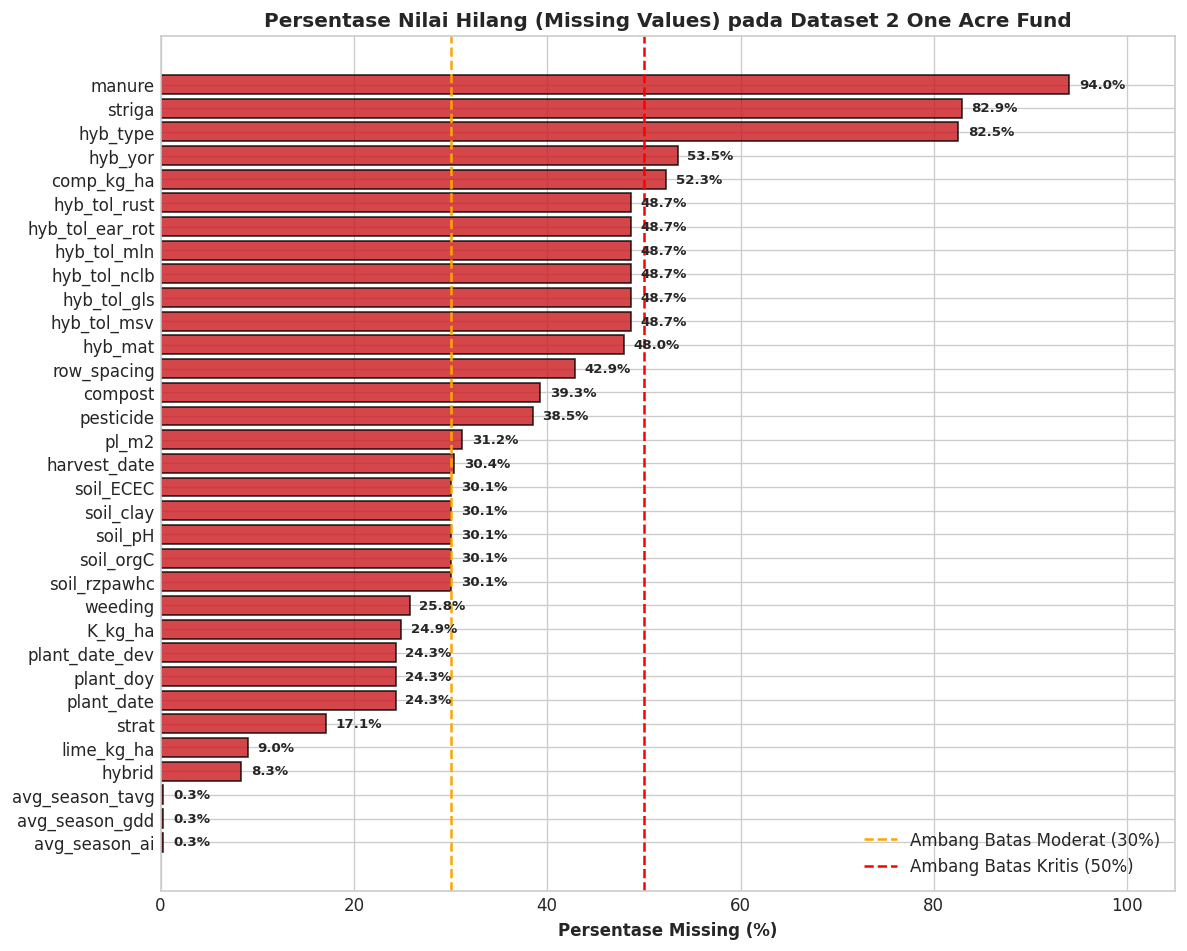

In [4]:
# Visualisasi Bar Horizontal Missing Values (>0%)
missing_plot_data = missing_summary[missing_summary['Missing Pct (%)'] > 0].sort_values(by='Missing Pct (%)', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(missing_plot_data.index, missing_plot_data['Missing Pct (%)'], color='#cb181d', alpha=0.8, edgecolor='black')
ax.axvline(30, color='orange', linestyle='--', linewidth=1.5, label='Ambang Batas Moderat (30%)')
ax.axvline(50, color='red', linestyle='--', linewidth=1.5, label='Ambang Batas Kritis (50%)')
ax.set_title("Persentase Nilai Hilang (Missing Values) pada Dataset 2 One Acre Fund", fontsize=12, fontweight='bold')
ax.set_xlabel("Persentase Missing (%)", fontsize=10, fontweight='bold')
ax.set_xlim(0, 105)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', fontsize=8, fontweight='semibold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [5]:
# 3.2 Pemeriksaan Duplikasi Baris
exact_dupes = df.duplicated().sum()
print(f"Duplikasi Baris Eksak (seluruh 53 kolom identik): {exact_dupes} baris (0.00%)")

# Pemeriksaan duplikasi spasio-temporal (apakah ada plot dengan waktu dan koordinat sama)
subset_keys = ['year', 'country', 'season', 'lat', 'lon', 'plant_date']
subset_dupes = df.duplicated(subset=subset_keys).sum()
print(f"Observasi Berbagi Koordinat & Waktu Sama {subset_keys}: {subset_dupes:,} baris ({subset_dupes/len(df)*100:.2f}%)")


Duplikasi Baris Eksak (seluruh 53 kolom identik): 0 baris (0.00%)
Observasi Berbagi Koordinat & Waktu Sama ['year', 'country', 'season', 'lat', 'lon', 'plant_date']: 1,996 baris (13.51%)


*Interpretasi Duplikasi:*
- **Duplikasi eksak adalah 0 baris**, menunjukkan integritas pencatatan baris tanpa penggandaan rekaman.
- Sebanyak 1.996 observasi berbagi titik koordinat dan waktu yang sama. Hal ini **bukan duplikasi data**, melainkan karakteristik operasional survei One Acre Fund di mana titik GPS diukur pada level sentroid kluster/desa (*village cluster centroid*) demi privasi petani kecil (*smallholder data governance*). Pada sentroid kluster yang sama, terdapat beberapa petani berbeda yang disurvei dengan input budidaya dan hasil panen yang bervariasi.


In [6]:
# 3.3 Analisis Nilai Nol pada Variabel Numerik
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
zero_records = []
for c in num_cols:
    z_cnt = int((df[c] == 0).sum())
    if z_cnt > 0:
        zero_records.append({
            'Kolom': c,
            'Jumlah Nol': z_cnt,
            'Persentase Nol (%)': round(z_cnt / len(df) * 100, 2),
            'Makna Nilai Nol': (
                "Tidak ada hasil panen yang tercatat (kejadian empiris)" if c == 'yield_kg_ha' else
                "Tanpa aplikasi pupuk Kalium (praktik umum petani Afrika)" if c == 'K_kg_ha' else
                "Tanpa aplikasi kapur pertanian (liming)" if c == 'lime_kg_ha' else
                "Plot tanpa pupuk Nitrogen kimia" if c == 'N_kg_ha' else
                "Plot tanpa pupuk Fosfat kimia" if c == 'P_kg_ha' else
                "Tepat pada titik acuan tanggal referensi" if c == 'plant_date_dev' else
                "Tanpa aplikasi kompos padat" if c == 'comp_kg_ha' else
                "Tidak ada presipitasi pada fase akhir" if c == 'season_prec_3' else
                "Nilai nol lainnya"
            )
        })
zero_df = pd.DataFrame(zero_records).sort_values(by='Jumlah Nol', ascending=False)
zero_df


,Kolom,Jumlah Nol,Persentase Nol (%),Makna Nilai Nol
8,lime_kg_ha,13123,88.8300,Tanpa aplikasi kapur pertanian (liming)
6,K_kg_ha,10114,68.4600,Tanpa aplikasi pupuk Kalium (praktik umum petani Afrika)
7,comp_kg_ha,5482,37.1100,Tanpa aplikasi kompos padat
5,P_kg_ha,3255,22.0300,Plot tanpa pupuk Fosfat kimia
4,N_kg_ha,2555,17.3000,Plot tanpa pupuk Nitrogen kimia
9,yield_kg_ha,263,1.7800,Tidak ada hasil panen yang tercatat (kejadian empiris)
2,plant_date_dev,185,1.2500,Tepat pada titik acuan tanggal referensi
3,pl_m2,10,0.0700,Nilai nol lainnya
0,lat,4,0.0300,Nilai nol lainnya
1,season_prec_3,3,0.0200,Tidak ada presipitasi pada fase akhir


In [7]:
# 3.4 Audit Anomali Nilai Ekstrem pada comp_kg_ha
comp_series = df['comp_kg_ha'].dropna()

print("Ringkasan Statistik comp_kg_ha (kg/ha):")
print(f"- Observasi Valid : {len(comp_series):,} baris (Missing: {df['comp_kg_ha'].isnull().sum():,})")
print(f"- Nilai Nol (0)   : {(comp_series == 0).sum():,} baris ({(comp_series == 0).mean()*100:.2f}% dari valid)")
print(f"- Rata-rata (Mean): {comp_series.mean():.2f} kg/ha")
print(f"- Median          : {comp_series.median():.2f} kg/ha")
print(f"- Persentil 75    : {comp_series.quantile(0.75):.2f} kg/ha")
print(f"- Persentil 90    : {comp_series.quantile(0.90):.2f} kg/ha")
print(f"- Persentil 95    : {comp_series.quantile(0.95):.2f} kg/ha")
print(f"- Persentil 99    : {comp_series.quantile(0.99):.2f} kg/ha")
print(f"- Nilai Maksimum  : {comp_series.max():.2f} kg/ha")
print(f"\nJumlah observasi > 10.000 kg/ha: {(comp_series > 10000).sum()} baris")
print(f"Jumlah observasi > 50.000 kg/ha: {(comp_series > 50000).sum()} baris")
print(f"Jumlah observasi > 100.000 kg/ha: {(comp_series > 100000).sum()} baris")

print("\n10 Nilai Tertinggi comp_kg_ha:")
display_top_comp = df[['country', 'year', 'compost', 'comp_kg_ha', 'yield_kg_ha']].dropna(subset=['comp_kg_ha']).sort_values(by='comp_kg_ha', ascending=False).head(10)
display_top_comp


Ringkasan Statistik comp_kg_ha (kg/ha):
- Observasi Valid : 7,047 baris (Missing: 7,726)
- Nilai Nol (0)   : 5,482 baris (77.79% dari valid)
- Rata-rata (Mean): 1872.87 kg/ha
- Median          : 0.00 kg/ha
- Persentil 75    : 0.00 kg/ha
- Persentil 90    : 7533.33 kg/ha
- Persentil 95    : 10972.72 kg/ha
- Persentil 99    : 20145.93 kg/ha
- Nilai Maksimum  : 166666.55 kg/ha
Jumlah observasi > 10.000 kg/ha: 381 baris
Jumlah observasi > 50.000 kg/ha: 10 baris
Jumlah observasi > 100.000 kg/ha: 1 baris
10 Nilai Tertinggi comp_kg_ha:


,country,year,compost,comp_kg_ha,yield_kg_ha
11951,rwanda,2019,True,166666.5501,4190.3787
12880,rwanda,2019,True,99999.9390,10589.6471
10977,rwanda,2020,True,89999.9357,6499.9780
6554,rwanda,2019,True,79999.9497,8838.5299
13873,rwanda,2020,True,79999.9497,4732.2721
13231,rwanda,2020,True,75806.4049,1774.8898
13427,rwanda,2019,True,74999.9481,3298.3093
13222,rwanda,2020,True,68181.7725,2010.2341
13209,rwanda,2018,True,62499.9588,3363.8450
13488,rwanda,2020,True,55555.5175,6774.3398


*Catatan Khusus Anomali `comp_kg_ha`:*
- Variabel dosis kompos (`comp_kg_ha`) memiliki nilai maksimum sebesar **$166.666,55	ext{ kg/ha}$** ($pprox 166,7	ext{ ton/ha}$), serta terdapat 381 baris observasi dengan nilai $> 10.000	ext{ kg/ha}$.
- Secara agronomis, nilai ini merupakan **pencilan ekstrem (*extreme outlier*)** yang melampaui batas kewajaran aplikasi kompos tanaman pangan pada umumnya.
- **Peringatan Metodologis:** Tidak dapat langsung dipastikan bahwa nilai ini diakibatkan oleh kesalahan konversi satuan (misalnya gram vs kg atau skala per luasan plot mikro vs per hektar) karena tidak ada bukti dokumentasi resmi terkait riwayat pencatatan enumerator.
- **Tindak Lanjut:** Nilai ini dicatat secara objektif sebagai **anomali yang memerlukan verifikasi dan perlakuan khusus pada tahap Data Preparation** (misalnya melalui pendekatan *capping/winsorization*, *trimming*, atau audit distribusi per negara).


In [8]:
# 3.5 Deteksi Outlier pada Variabel Numerik Utama (Metode IQR)
outlier_records = []
for col in ['yield_kg_ha', 'N_kg_ha', 'P_kg_ha', 'K_kg_ha', 'elev', 'season_prec', 'avg_season_tavg', 'pl_m2', 'comp_kg_ha']:
    series = df[col].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_b = q1 - 1.5 * iqr
    upper_b = q3 + 1.5 * iqr
    
    n_out_low = (series < lower_b).sum()
    n_out_high = (series > upper_b).sum()
    total_out = n_out_low + n_out_high
    pct_out = total_out / len(series) * 100
    
    outlier_records.append({
        'Variabel': col,
        'Q1 (25%)': round(q1, 2),
        'Median': round(series.median(), 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Batas Bawah': round(lower_b, 2),
        'Batas Atas': round(upper_b, 2),
        'Outlier Atas': int(n_out_high),
        'Outlier Bawah': int(n_out_low),
        'Total Outlier': int(total_out),
        'Outlier Pct (%)': round(pct_out, 2)
    })

pd.DataFrame(outlier_records)


,Variabel,Q1 (25%),Median,Q3 (75%),IQR,Batas Bawah,Batas Atas,Outlier Atas,Outlier Bawah,Total Outlier,Outlier Pct (%)
0,yield_kg_ha,1743.9900,2713.8700,3945.2200,2201.2300,-1557.8600,7247.0700,296,0,296,2.0000
1,N_kg_ha,7.1200,22.2400,51.2400,44.1300,-59.0700,117.4400,152,0,152,1.0300
2,P_kg_ha,3.0900,16.4700,24.7100,21.6200,-29.3400,57.1400,163,0,163,1.1000
3,K_kg_ha,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,982,0,982,8.8500
4,elev,1382.0000,1582.0000,1795.0000,413.0000,762.5000,2414.5000,154,115,269,1.8200
5,season_prec,739.3600,902.5200,1109.5100,370.1600,184.1200,1664.7500,164,0,164,1.1100
6,avg_season_tavg,18.6800,20.0600,21.0200,2.3400,15.1800,24.5300,115,202,317,2.1500
7,pl_m2,2.6200,3.4000,4.2100,1.5900,0.2300,6.5900,477,11,488,4.8000
8,comp_kg_ha,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1565,0,1565,22.2100


In [9]:
# 3.6 Pemeriksaan Kolom dengan Variasi Sangat Rendah (Near-Zero Variance)
low_var_cols = []
for col in df.columns:
    n_uniq = df[col].nunique(dropna=False)
    top_freq_pct = (df[col].value_counts(normalize=True, dropna=False).iloc[0]) * 100
    if top_freq_pct >= 90.0:
        low_var_cols.append({
            'Kolom': col,
            'Nilai Unik': n_uniq,
            'Nilai Dominan': str(df[col].value_counts(dropna=False).index[0]),
            'Dominasi (%)': round(top_freq_pct, 2),
            'Catatan': "Variasi sangat rendah, kurang informatif untuk pemodelan"
        })

low_var_df = pd.DataFrame(low_var_cols)
low_var_df


,Kolom,Nilai Unik,Nilai Dominan,Dominasi (%),Catatan
0,season,2,first season,93.9700,"Variasi sangat rendah, kurang informatif untuk pemodelan"
1,manure,3,nan,94.0000,"Variasi sangat rendah, kurang informatif untuk pemodelan"
2,disease,2,False,97.4200,"Variasi sangat rendah, kurang informatif untuk pemodelan"
3,water_excess,2,False,92.0700,"Variasi sangat rendah, kurang informatif untuk pemodelan"


### 3.7 Rekomendasi Penanganan Kualitas Data (Tabel Keputusan)
| Masalah Kualitas | Temuan Data | Rekomendasi Penanganan | Alasan Metodologis |
|---|---|---|---|
| **Missing Values Kritis (>50%)** | `manure` (94%), `hyb_type` (82%), `striga` (83%), `hyb_yor` (53%), `comp_kg_ha` (52%) | **Gugurkan dari fitur prediktor utama** atau buat indikator biner terpisah (missing vs recorded). | Imputasi pada missingness >50% memperkenalkan bias statistik buatan yang sangat tinggi. |
| **Missing Values Moderat (20–45%)** | `soil_*` (~30%), `pl_m2` (31%), `row_spacing` (43%), `pesticide` (38%) | Gunakan **imputasi berbasis kluster spasial/regional** atau algoritma berbasis pohon (*tree-based*) yang tangguh menangani missing values. | Nilai tanah memiliki autokorelasi spasial tinggi; mengisi dengan median regional mempertahankan sifat geofisik lokal. |
| **Nilai Nol pada Input Agronomi** | `N_kg_ha` (17,3%), `P_kg_ha` (22,0%), `K_kg_ha` (68,5%), `lime_kg_ha` (88,8%) | **Pertahankan sebagai nilai 0 asli**, jangan diubah menjadi NaN. | Nilai nol mencerminkan fakta budidaya nyata bahwa petani kecil subsisten tidak membeli/mengaplikasikan pupuk tersebut. |
| **Anomali Ekstrem `comp_kg_ha`** | Nilai maksimum mencapai $166.666,55	ext{ kg/ha}$; 381 baris $> 10.000	ext{ kg/ha}$ | **Verifikasi dan putuskan penanganan pada Data Preparation** (misal: capping/winsorizing atau trimming). | Merupakan pencilan ekstrem tanpa verifikasi resmi mengenai penyebabnya; perlu mitigasi distorsi model. |
| **Outlier pada Target Yield** | 296 baris (2,00%) berada di atas 7.247 kg/ha (maksimal 11.139 kg/ha) | **Jangan langsung dibuang**. Gunakan evaluasi loss yang robust (Huber/MAE). | Nilai 7.000–11.000 kg/ha secara agronomis masih mungkin dicapai pada varietas hibrida intensif di dataran tinggi Rwanda/Kenya. |


---
## 4. Target Variable Assessment (`yield_kg_ha`)

Variabel target yang dianalisis adalah `yield_kg_ha` (hasil panen biji jagung pipilan kering dalam satuan kilogram per hektar).


In [10]:
# 4.1 Statistik Deskriptif Target
y = df['yield_kg_ha']

q1 = y.quantile(0.25)
q3 = y.quantile(0.75)
iqr = q3 - q1

target_metrics = {
    'Parameter Statistik': [
        'Jumlah Observasi Total', 'Data Valid (Non-Null)', 'Missing Values', 'Persentase Missing',
        'Nilai Minimum', 'Kuartil Bawah (Q1 / 25%)', 'Median (Q2 / 50%)', 'Rata-rata (Mean)',
        'Kuartil Atas (Q3 / 75%)', 'Nilai Maksimum', 'Interquartile Range (IQR)',
        'Standar Deviasi', 'Koefisien Variasi (CV %)', 'Skewness (Kemencengan)',
        'Kurtosis', 'Jumlah Nilai Nol (Zero Yield)', 'Persentase Nilai Nol (%)',
        'Batas Outlier IQR Atas (Q3 + 1.5*IQR)', 'Jumlah Outlier IQR Atas', 'Persentase Outlier (%)'
    ],
    'Nilai': [
        f"{len(y):,}", f"{y.notnull().sum():,}", f"{y.isnull().sum()}", f"{y.isnull().mean()*100:.2f}%",
        f"{y.min():.2f} kg/ha", f"{q1:.2f} kg/ha", f"{y.median():.2f} kg/ha", f"{y.mean():.2f} kg/ha",
        f"{q3:.2f} kg/ha", f"{y.max():.2f} kg/ha", f"{iqr:.2f} kg/ha",
        f"{y.std():.2f} kg/ha", f"{(y.std()/y.mean())*100:.2f}%", f"{y.skew():.4f}",
        f"{y.kurt():.4f}", f"{(y == 0).sum():,}", f"{(y == 0).mean()*100:.2f}%",
        f"{q3 + 1.5 * iqr:.2f} kg/ha", f"{(y > (q3 + 1.5 * iqr)).sum():,}", f"{(y > (q3 + 1.5 * iqr)).mean()*100:.2f}%"
    ]
}
pd.DataFrame(target_metrics)


,Parameter Statistik,Nilai
0,Jumlah Observasi Total,"14,773"
1,Data Valid (Non-Null),"14,773"
2,Missing Values,0
3,Persentase Missing,0.00%
4,Nilai Minimum,0.00 kg/ha
5,Kuartil Bawah (Q1 / 25%),1743.99 kg/ha
6,Median (Q2 / 50%),2713.87 kg/ha
7,Rata-rata (Mean),2969.06 kg/ha
8,Kuartil Atas (Q3 / 75%),3945.22 kg/ha
9,Nilai Maksimum,11139.13 kg/ha


<ast>:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


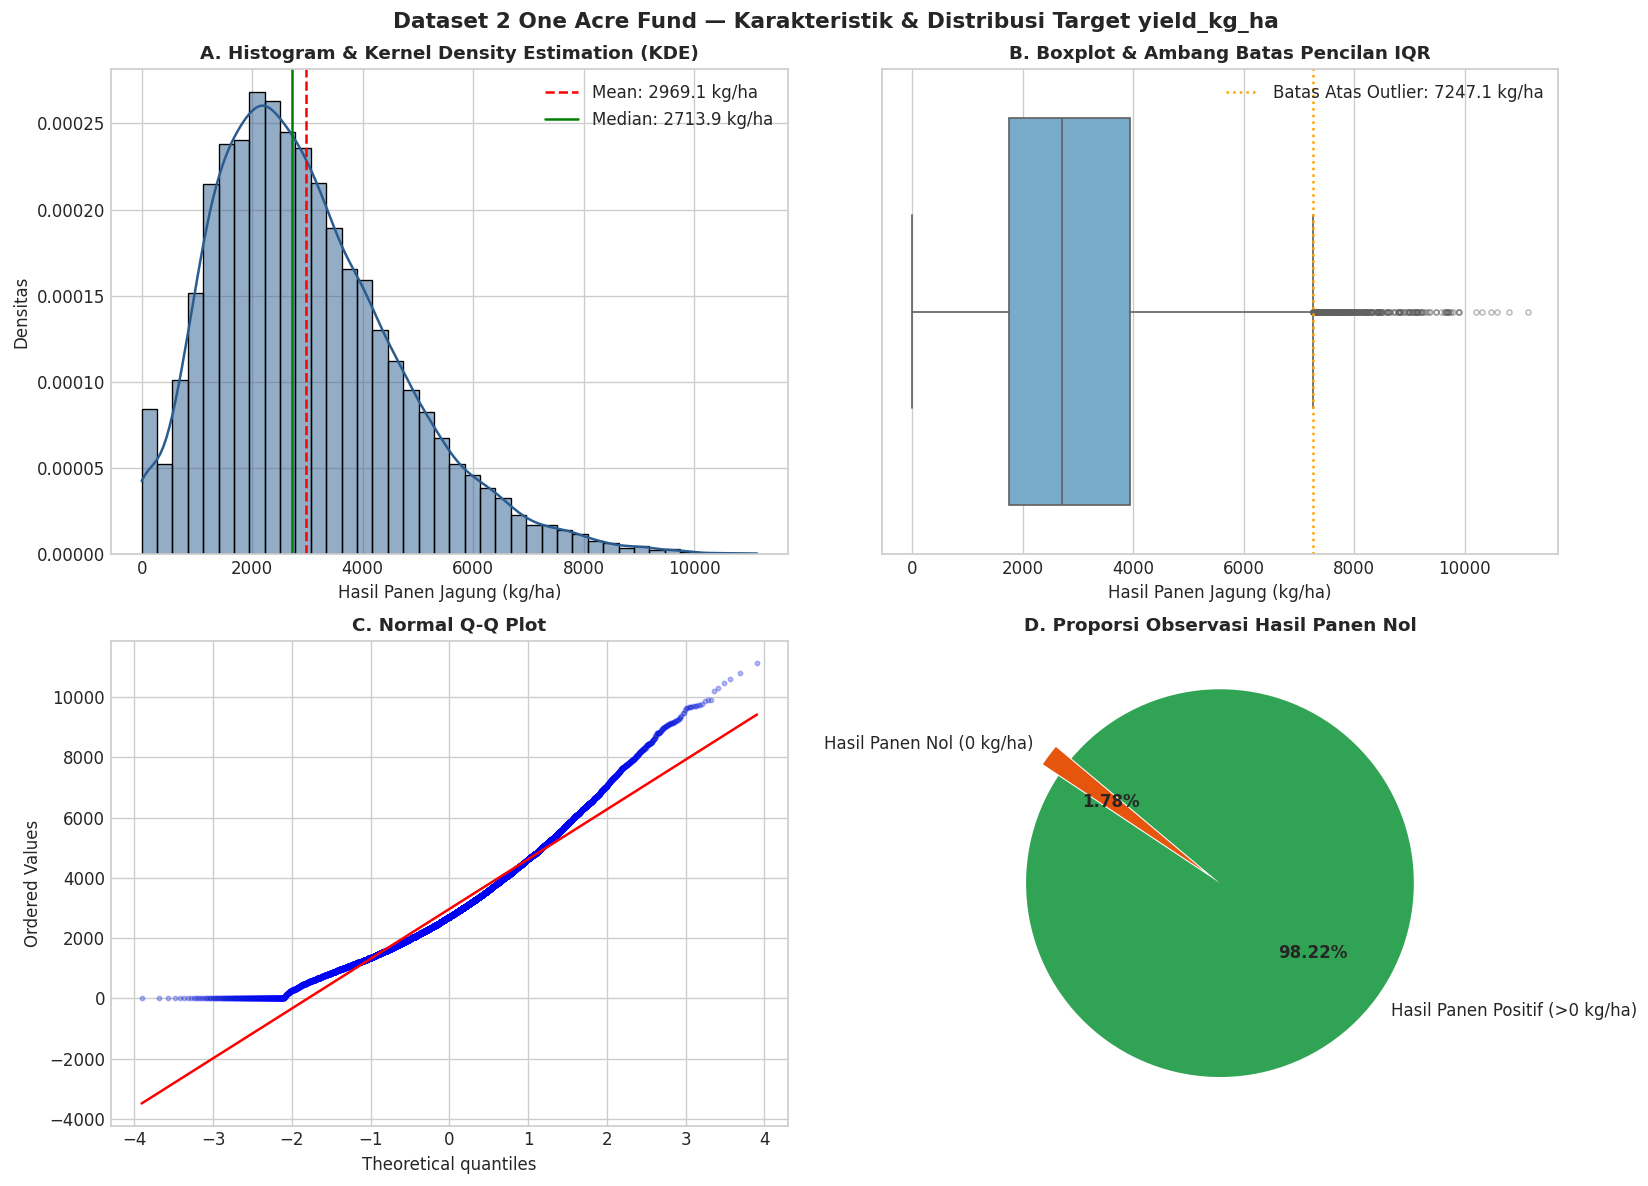

In [11]:
# 4.2 Visualisasi Komprehensif Target: Histogram, Boxplot, QQ-Plot, dan Proporsi Zero Yield
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2)

# Subplot 1: Histogram + KDE
ax1 = fig.add_subplot(gs[0, 0])
sns.histplot(y, kde=True, color='#2b5c8f', bins=40, ax=ax1, stat='density')
ax1.axvline(y.mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {y.mean():.1f} kg/ha")
ax1.axvline(y.median(), color='green', linestyle='-', linewidth=1.5, label=f"Median: {y.median():.1f} kg/ha")
ax1.set_title("A. Histogram & Kernel Density Estimation (KDE)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Hasil Panen Jagung (kg/ha)")
ax1.set_ylabel("Densitas")
ax1.legend(loc='upper right')

# Subplot 2: Boxplot
ax2 = fig.add_subplot(gs[0, 1])
sns.boxplot(x=y, color='#6baed6', ax=ax2, flierprops={'marker':'o', 'markersize':3, 'alpha':0.4})
ax2.axvline(q3 + 1.5 * iqr, color='orange', linestyle=':', linewidth=1.5, label=f"Batas Atas Outlier: {q3 + 1.5 * iqr:.1f} kg/ha")
ax2.set_title("B. Boxplot & Ambang Batas Pencilan IQR", fontsize=11, fontweight='bold')
ax2.set_xlabel("Hasil Panen Jagung (kg/ha)")
ax2.legend(loc='upper right')

# Subplot 3: Normal Q-Q Plot
ax3 = fig.add_subplot(gs[1, 0])
stats.probplot(y, dist="norm", plot=ax3)
ax3.get_lines()[0].set_markerfacecolor('#2b5c8f')
ax3.get_lines()[0].set_markersize(2.5)
ax3.get_lines()[0].set_alpha(0.3)
ax3.get_lines()[1].set_color('red')
ax3.set_title("C. Normal Q-Q Plot", fontsize=11, fontweight='bold')

# Subplot 4: Proporsi Zero Yield
ax4 = fig.add_subplot(gs[1, 1])
zero_vs_prod = pd.Series({
    'Hasil Panen Nol (0 kg/ha)': (y == 0).sum(),
    'Hasil Panen Positif (>0 kg/ha)': (y > 0).sum()
})
colors = ['#e6550d', '#31a354']
wedges, texts, autotexts = ax4.pie(zero_vs_prod, labels=zero_vs_prod.index, autopct='%1.2f%%',
                                  colors=colors, startangle=140, explode=(0.1, 0))
for at in autotexts:
    at.set_fontweight('bold')
ax4.set_title("D. Proporsi Observasi Hasil Panen Nol", fontsize=11, fontweight='bold')

plt.suptitle("Dataset 2 One Acre Fund — Karakteristik & Distribusi Target yield_kg_ha", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


*Catatan Temuan Data Hasil Panen Nol (Zero Yield):*
- Sebanyak **263 observasi (1,78%)** tercatat bernilai $0	ext{ kg/ha}$.
- Temuan ini merupakan **fakta empiris pencatatan data lapangan** di mana tidak ada hasil panen jagung yang diperoleh pada plot tersebut.
- Karena dataset tidak memuat variabel penjelasan penyebab kehilangan panen per baris, **penyebab spesifik dari nilai nol ini tidak dapat dipastikan tanpa bukti dokumentasi resmi**. Strategi penanganan 263 baris ini akan diputuskan secara terstruktur pada tahap Data Preparation.


In [12]:
# 4.3 Analisis Target Berdasarkan Negara
target_country = df.groupby('country')['yield_kg_ha'].agg(
    Observasi='count',
    Mean='mean',
    Std='std',
    Min='min',
    Q1=lambda x: x.quantile(0.25),
    Median='median',
    Q3=lambda x: x.quantile(0.75),
    Max='max',
    Zero_Count=lambda x: (x == 0).sum()
).reset_index()
target_country['Zero_Pct (%)'] = (target_country['Zero_Count'] / target_country['Observasi'] * 100).round(2)
target_country.sort_values(by='Median', ascending=False)


,country,Observasi,Mean,Std,Min,Q1,Median,Q3,Max,Zero_Count,Zero_Pct (%)
3,rwanda,2080,3417.1570,1828.7046,0.0000,2068.5023,3277.2913,4576.8712,11139.1308,61,2.9300
1,kenya,7258,3019.7246,1707.2077,0.0000,1806.8089,2764.5533,3973.6210,9903.5438,144,1.9800
4,tanzania,3710,2961.2938,1609.4386,0.0000,1762.4974,2689.3307,3926.3609,9701.3100,58,1.5600
6,zambia,861,2575.9706,1438.9959,61.1342,1494.3901,2377.4389,3396.3413,7730.0783,0,0.0000
5,uganda,109,1948.6416,1178.7261,54.3401,991.7072,1711.7138,2621.9107,5488.3522,0,0.0000
0,burundi,640,1903.1536,1044.0932,293.4500,1127.5084,1662.8835,2532.0547,4791.0207,0,0.0000
2,nigeria,115,1759.9180,824.7191,166.6666,1146.3521,1638.8877,2083.3319,4791.6634,0,0.0000


In [13]:
# 4.4 Analisis Target Berdasarkan Tahun Survei
target_year = df.groupby('year')['yield_kg_ha'].agg(
    Observasi='count',
    Mean='mean',
    Std='std',
    Min='min',
    Median='median',
    Max='max',
    Zero_Count=lambda x: (x == 0).sum()
).reset_index()
target_year['Zero_Pct (%)'] = (target_year['Zero_Count'] / target_year['Observasi'] * 100).round(2)
target_year.sort_values(by='year')


,year,Observasi,Mean,Std,Min,Median,Max,Zero_Count,Zero_Pct (%)
0,2016,2437,2520.9857,1323.4412,0.0000,2281.8563,9668.2000,13,0.5300
1,2017,1094,3217.0756,1848.1079,0.0000,2862.2962,9903.5438,18,1.6500
2,2018,3187,2939.3097,1601.3976,0.0000,2784.6893,10473.2074,81,2.5400
3,2019,4333,3124.8657,1843.2266,0.0000,2859.6486,11139.1308,98,2.2600
4,2020,3607,3074.2535,1678.2094,0.0000,2891.0485,10798.7350,53,1.4700
5,2022,115,1759.9180,824.7191,166.6666,1638.8877,4791.6634,0,0.0000


---
## 5. Exploratory Data Analysis (EDA)

Pada bagian ini, dilakukan eksplorasi hubungan antara variabel prediktor potensial dengan target hasil panen jagung.


In [14]:
# 5.1 Evaluasi Rinci Variabel hybrid terhadap yield_kg_ha
print("Pemeriksaan Rinci Variabel hybrid:")
print("Tipe data kolom hybrid:", df['hybrid'].dtype)
print("Distribusi nilai mentah:")
print(df['hybrid'].value_counts(dropna=False))

# Pembuatan tabel evaluasi komparatif lengkap dengan filter yang transparan
hybrid_eval_list = []
for label, cond, filter_desc in [
    ("Benih Hibrida (True)", df['hybrid'] == True, "df['hybrid'] == True"),
    ("Bukan Hibrida (False)", df['hybrid'] == False, "df['hybrid'] == False"),
    ("Data Hilang (NaN)", df['hybrid'].isna(), "df['hybrid'].isna()"),
    ("Total Seluruh Data", df['hybrid'].notnull() | df['hybrid'].isnull(), "Seluruh Observasi")
]:
    sub_y = df[cond]['yield_kg_ha']
    hybrid_eval_list.append({
        'Kategori hybrid': label,
        'Filter Pandas': filter_desc,
        'Jumlah Observasi (N)': len(sub_y),
        'Proporsi (%)': round(len(sub_y) / len(df) * 100, 2),
        'Mean (kg/ha)': round(sub_y.mean(), 2),
        'Median (kg/ha)': round(sub_y.median(), 2),
        'Std (kg/ha)': round(sub_y.std(), 2),
        'Min (kg/ha)': round(sub_y.min(), 2),
        'Max (kg/ha)': round(sub_y.max(), 2)
    })

df_hybrid_audit = pd.DataFrame(hybrid_eval_list)
df_hybrid_audit


Pemeriksaan Rinci Variabel hybrid:
Tipe data kolom hybrid: object
Distribusi nilai mentah:
hybrid
True     10734
False     2809
NaN       1230
Name: count, dtype: int64


,Kategori hybrid,Filter Pandas,Jumlah Observasi (N),Proporsi (%),Mean (kg/ha),Median (kg/ha),Std (kg/ha),Min (kg/ha),Max (kg/ha)
0,Benih Hibrida (True),df['hybrid'] == True,10734,72.6600,3185.6500,2934.3700,1706.1800,0.0000,10798.7400
1,Bukan Hibrida (False),df['hybrid'] == False,2809,19.0100,2264.3800,1996.5900,1461.5300,0.0000,11139.1300
2,Data Hilang (NaN),df['hybrid'].isna(),1230,8.3300,2688.2100,2350.4400,1497.6000,0.0000,9701.3100
3,Total Seluruh Data,Seluruh Observasi,14773,100.0000,2969.0600,2713.8700,1686.0700,0.0000,11139.1300


<ast>:7: FutureWarning: 
Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.
<ast>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


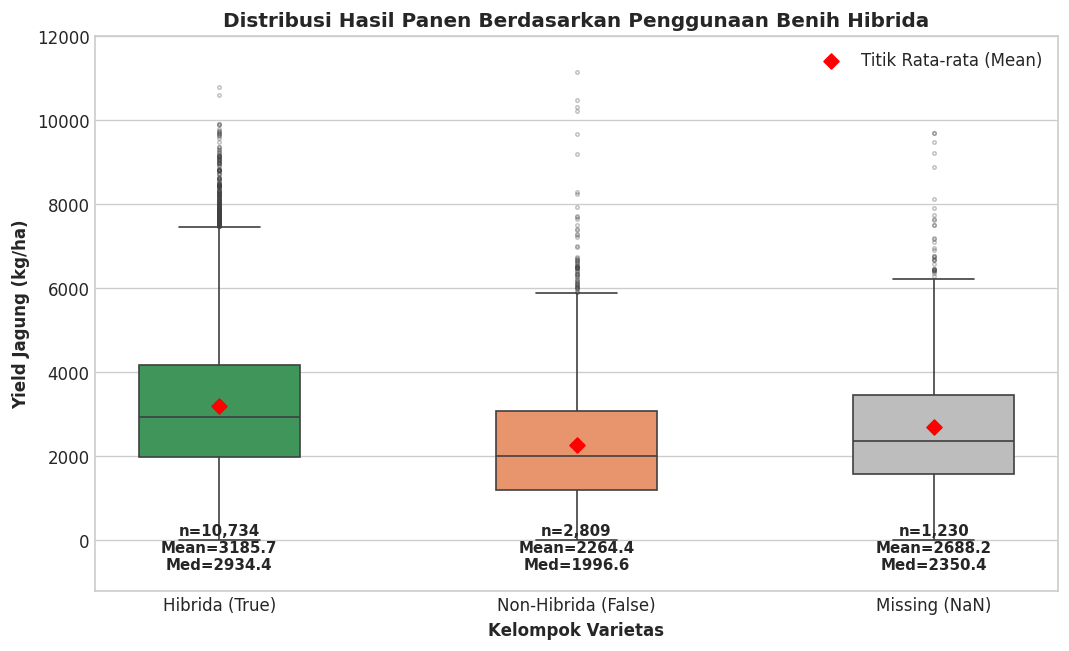

In [15]:
# Visualisasi Komparasi Yield Berdasarkan Variabel hybrid
fig, ax = plt.subplots(figsize=(9, 5.5))
df_plot_hyb = df.copy()
df_plot_hyb['hybrid_group'] = df_plot_hyb['hybrid'].map({True: 'Hibrida (True)', False: 'Non-Hibrida (False)'}).fillna('Missing (NaN)')
group_order = ['Hibrida (True)', 'Non-Hibrida (False)', 'Missing (NaN)']

sns.boxplot(data=df_plot_hyb, x='hybrid_group', y='yield_kg_ha', order=group_order,
            palette=['#31a354', '#fc8d59', '#bdbdbd'], ax=ax, width=0.45,
            flierprops={'marker':'o', 'markersize':2, 'alpha':0.3})

means_h = df_plot_hyb.groupby('hybrid_group')['yield_kg_ha'].mean()
counts_h = df_plot_hyb.groupby('hybrid_group')['yield_kg_ha'].count()
medians_h = df_plot_hyb.groupby('hybrid_group')['yield_kg_ha'].median()

for i, grp in enumerate(group_order):
    m_val = means_h[grp]
    med_val = medians_h[grp]
    n_val = counts_h[grp]
    ax.scatter(i, m_val, color='red', marker='D', s=40, zorder=5)
    ax.text(i, -700, f"n={n_val:,}\nMean={m_val:.1f}\nMed={med_val:.1f}", ha='center', fontsize=9, fontweight='semibold')

ax.set_ylim(-1200, 12000)
ax.set_title("Distribusi Hasil Panen Berdasarkan Penggunaan Benih Hibrida", fontsize=12, fontweight='bold')
ax.set_xlabel("Kelompok Varietas", fontsize=10, fontweight='bold')
ax.set_ylabel("Yield Jagung (kg/ha)", fontsize=10, fontweight='bold')
ax.scatter([], [], color='red', marker='D', s=40, label='Titik Rata-rata (Mean)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


<ast>:5: FutureWarning: 
Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.
<ast>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


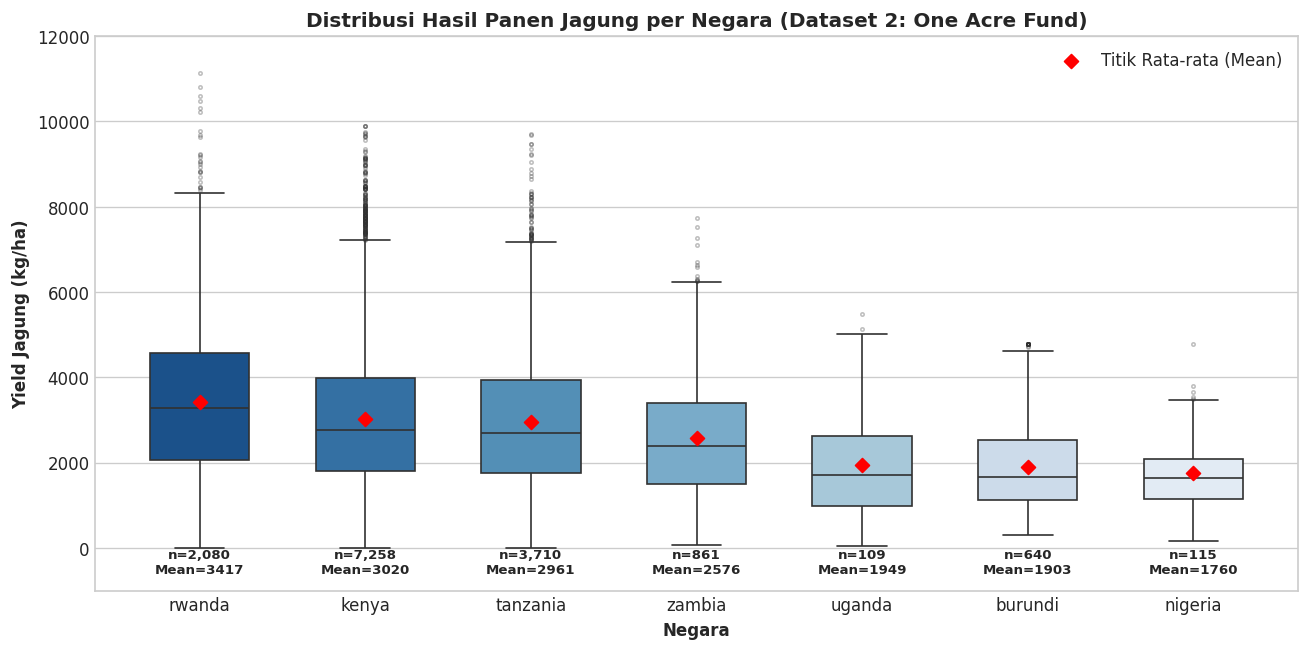

In [16]:
# 5.2 Distribusi Target Berdasarkan Negara
plt.figure(figsize=(11, 5.5))
country_order = df.groupby('country')['yield_kg_ha'].median().sort_values(ascending=False).index
palette = sns.color_palette("Blues_r", len(country_order))
ax = sns.boxplot(data=df, x='country', y='yield_kg_ha', order=country_order, palette=palette, width=0.6,
                 flierprops={'marker':'o', 'markersize':2, 'alpha':0.3})

means = df.groupby('country')['yield_kg_ha'].mean()
counts = df.groupby('country')['yield_kg_ha'].count()
for i, country in enumerate(country_order):
    mean_val = means[country]
    n_val = counts[country]
    ax.scatter(i, mean_val, color='red', marker='D', s=35, zorder=5)
    ax.text(i, -600, f"n={n_val:,}\nMean={mean_val:.0f}", ha='center', fontsize=8, fontweight='semibold')

ax.set_ylim(-1000, 12000)
ax.set_title("Distribusi Hasil Panen Jagung per Negara (Dataset 2: One Acre Fund)", fontsize=12, fontweight='bold')
ax.set_xlabel("Negara", fontsize=10, fontweight='bold')
ax.set_ylabel("Yield Jagung (kg/ha)", fontsize=10, fontweight='bold')
ax.scatter([], [], color='red', marker='D', s=35, label='Titik Rata-rata (Mean)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


<ast>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


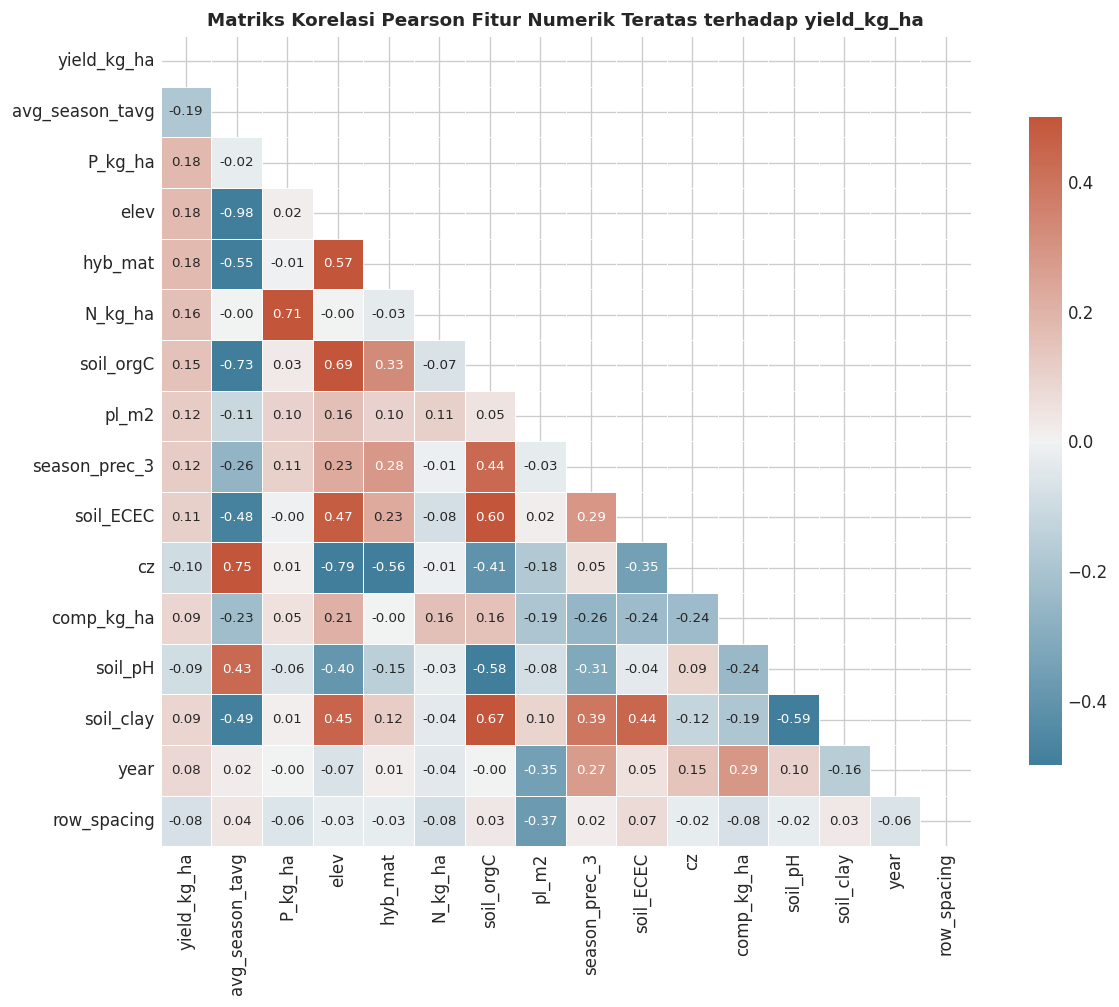

In [17]:
# 5.3 Matriks Korelasi Variabel Numerik Utama dengan Target
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_target = df[num_cols].corr()['yield_kg_ha'].sort_values(ascending=False)

top_corr_vars = corr_target.abs().sort_values(ascending=False).head(16).index.tolist()
corr_matrix = df[top_corr_vars].corr()

plt.figure(figsize=(11, 8.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-0.5, vmax=0.5, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot=True, fmt='.2f', annot_kws={"size": 8})
plt.title("Matriks Korelasi Pearson Fitur Numerik Teratas terhadap yield_kg_ha", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


<ast>:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


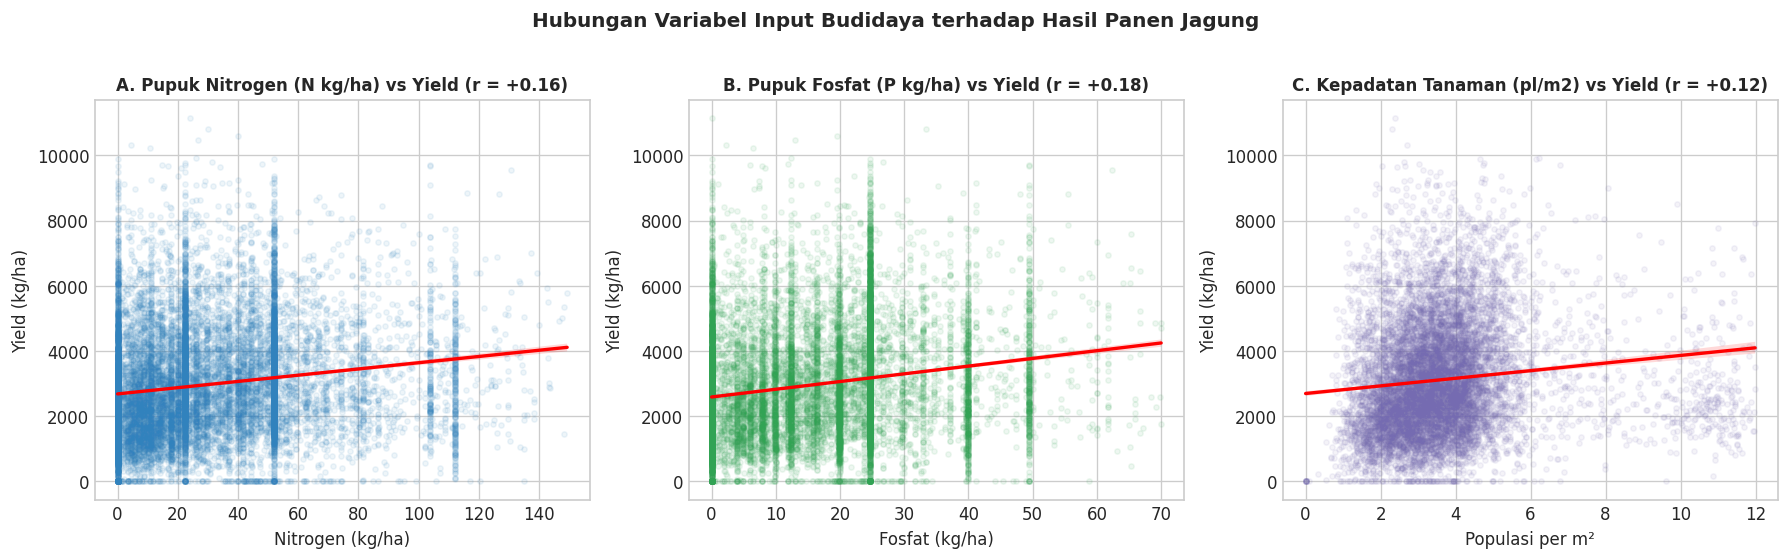

In [18]:
# 5.4 Hubungan Faktor Budidaya & Pemupukan terhadap Yield
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# N_kg_ha vs yield
sns.regplot(data=df[df['N_kg_ha'] <= 150], x='N_kg_ha', y='yield_kg_ha',
            scatter_kws={'alpha':0.08, 'color':'#3182bd', 's':10},
            line_kws={'color':'red', 'linewidth':2}, ax=axes[0])
axes[0].set_title("A. Pupuk Nitrogen (N kg/ha) vs Yield (r = +0.16)", fontweight='bold', fontsize=10)
axes[0].set_xlabel("Nitrogen (kg/ha)")
axes[0].set_ylabel("Yield (kg/ha)")

# P_kg_ha vs yield
sns.regplot(data=df[df['P_kg_ha'] <= 70], x='P_kg_ha', y='yield_kg_ha',
            scatter_kws={'alpha':0.08, 'color':'#31a354', 's':10},
            line_kws={'color':'red', 'linewidth':2}, ax=axes[1])
axes[1].set_title("B. Pupuk Fosfat (P kg/ha) vs Yield (r = +0.18)", fontweight='bold', fontsize=10)
axes[1].set_xlabel("Fosfat (kg/ha)")
axes[1].set_ylabel("Yield (kg/ha)")

# pl_m2 vs yield
sns.regplot(data=df.dropna(subset=['pl_m2']), x='pl_m2', y='yield_kg_ha',
            scatter_kws={'alpha':0.08, 'color':'#756bb1', 's':10},
            line_kws={'color':'red', 'linewidth':2}, ax=axes[2])
axes[2].set_title("C. Kepadatan Tanaman (pl/m2) vs Yield (r = +0.12)", fontweight='bold', fontsize=10)
axes[2].set_xlabel("Populasi per m²")
axes[2].set_ylabel("Yield (kg/ha)")

plt.suptitle("Hubungan Variabel Input Budidaya terhadap Hasil Panen Jagung", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


<ast>:6: FutureWarning: 
Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.
<ast>:13: FutureWarning: 
Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.
<ast>:20: FutureWarning: 
Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.
<ast>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


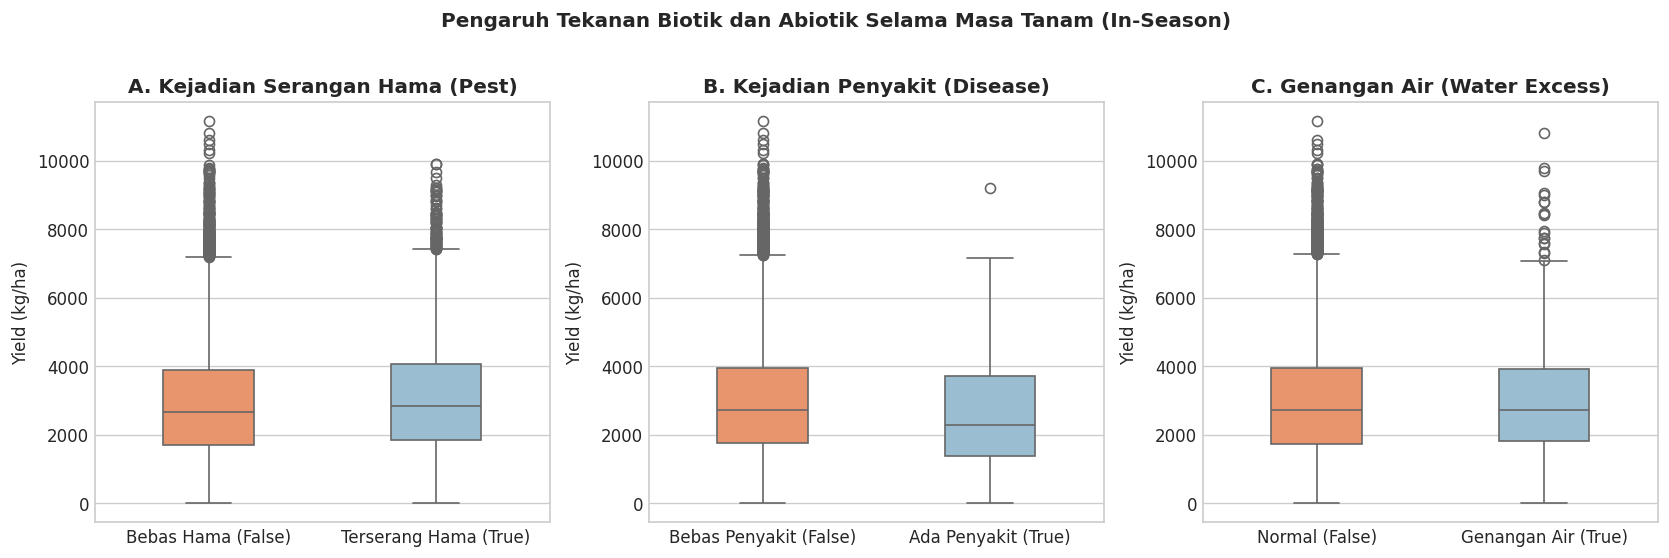

In [19]:
# 5.5 Dampak Tekanan Biotik dan Abiotik Lapangan (In-Season Factors)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

# Pest impact
df['pest_lbl'] = df['pest'].map({True: 'Terserang Hama (True)', False: 'Bebas Hama (False)'})
sns.boxplot(data=df, x='pest_lbl', y='yield_kg_ha', palette=['#fc8d59', '#91bfdb'], ax=axes[0], width=0.4)
axes[0].set_title("A. Kejadian Serangan Hama (Pest)", fontweight='bold')
axes[0].set_xlabel("")
axes[0].set_ylabel("Yield (kg/ha)")

# Disease impact
df['disease_lbl'] = df['disease'].map({True: 'Ada Penyakit (True)', False: 'Bebas Penyakit (False)'})
sns.boxplot(data=df, x='disease_lbl', y='yield_kg_ha', palette=['#fc8d59', '#91bfdb'], ax=axes[1], width=0.4)
axes[1].set_title("B. Kejadian Penyakit (Disease)", fontweight='bold')
axes[1].set_xlabel("")
axes[1].set_ylabel("Yield (kg/ha)")

# Water excess impact
df['water_lbl'] = df['water_excess'].map({True: 'Genangan Air (True)', False: 'Normal (False)'})
sns.boxplot(data=df, x='water_lbl', y='yield_kg_ha', palette=['#fc8d59', '#91bfdb'], ax=axes[2], width=0.4)
axes[2].set_title("C. Genangan Air (Water Excess)", fontweight='bold')
axes[2].set_xlabel("")
axes[2].set_ylabel("Yield (kg/ha)")

plt.suptitle("Pengaruh Tekanan Biotik dan Abiotik Selama Masa Tanam (In-Season)", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 6. Feature Relevance dan Evaluasi Skenario Fitur (Pre-Planting vs In-Season vs Post-Harvest)

Penelitian ini memerlukan estimasi hasil panen untuk **perencanaan kapasitas produksi**. Oleh karena itu, klasifikasi fitur harus ditinjau secara ketat berdasarkan **waktu ketersediaan informasi (*chronological availability*)** saat model dioperasikan:

### 6.1 Pemisahan Tegas Kategori Waktu Ketersediaan Fitur

```
+---------------------------------------------------------------------------------------------------+
| 1. SKENARIO PRE-PLANTING (Sebelum Benih Ditanam)                                                 |
| Variabel yang secara logis dan fisik SUDAH DIKETAHUI sebelum penanaman dimulai:                   |
| - Topografi & Lokasi: elev, twi, lat, lon                                                         |
| - Karakteristik Kimia & Fisik Tanah: soil_pH, soil_clay, soil_orgC, soil_ECEC, soil_rzpawhc       |
| - Iklim Dasar / Makro Historis: avg_season_gdd, avg_season_ai, avg_season_tavg                    |
| - Rencana & Keputusan Awal Petani: hybrid (pilihan benih), hyb_mat (rating kematangan benih),     |
|   plant_doy (jadwal hari tanam yang direncanakan).                                                |
| *Catatan:* Bebas dari risiko data leakage dan paling ideal untuk perencanaan kapasitas pakan awal.|
+---------------------------------------------------------------------------------------------------+
| 2. SKENARIO IN-SEASON (Sepanjang Masa Pertumbuhan Tanaman)                                        |
| Variabel yang BARU TERJADI, DIAPLIKASIKAN, ATAU DIAMATI setelah tanaman tumbuh:                   |
| - Presipitasi Aktual per Fase: season_prec, season_prec_1, season_prec_2, season_prec_3           |
| - Input Budidaya & Pemupukan: N_kg_ha, P_kg_ha, K_kg_ha, fert_in_hole, lime_kg_ha, comp_kg_ha,     |
|   pl_m2 (kepadatan populasi tanaman tegak), row_spacing, weeding                                  |
| - Kejadian Hama, Penyakit, dan Proteksi: pest, disease, water_excess, pesticide, striga           |
| *PENEGASAN PENTING:* Variabel pest, disease, water_excess, dan pesticide TIDAK BISA dimasukkan   |
| ke dalam model pre-planting karena serangan hama dan penyemprotan pestisida baru terjadi in-season|
+---------------------------------------------------------------------------------------------------+
| 3. POST-HARVEST / DATA LEAKAGE RISKS (Wajib Dieliminasi dari Model Perencanaan)                   |
| - harvest_date: Tanggal panen riil; jika dihitung durasinya (harvest_date - plant_date), akan      |
|   membocorkan informasi panjang siklus hidup tanaman yang hanya diketahui setelah panen selesai.   |
+---------------------------------------------------------------------------------------------------+
| 4. IDENTITAS ADMINISTRATIF / TIDAK TRANSFERABLE                                                   |
| - iso: Redundan dengan country                                                                    |
| - strat: Kode sampling survei internal One Acre Fund                                              |
| - cz: Kode zona agroklimat spesifik regional Afrika                                               |
+---------------------------------------------------------------------------------------------------+
| 5. MISSINGNESS TINGGI (>50%)                                                                      |
| - manure (94,00%), striga (82,91%), hyb_type (82,52%), hyb_yor (53,50%), comp_kg_ha (52,30%)      |
+---------------------------------------------------------------------------------------------------+
```


In [20]:
# Tabel Ringkasan Evaluasi Peran Fitur
feature_eval_records = [
    {'Grup Fitur': 'Kandidat Pre-Planting', 'Variabel': 'elev, twi, soil_pH, soil_clay, soil_orgC, soil_ECEC, soil_rzpawhc, plant_doy, hybrid, hyb_mat', 'Rekomendasi': 'Direkomendasikan (Tier 1)', 'Alasan': 'Tersedia sebelum tanam, bebas data leakage, cocok untuk perencanaan kapasitas awal'},
    {'Grup Fitur': 'Kandidat In-Season', 'Variabel': 'season_prec (1,2,3), N_kg_ha, P_kg_ha, fert_in_hole, pl_m2, weeding, pesticide, pest, disease, water_excess', 'Rekomendasi': 'Direkomendasikan (Tier 2 / In-Season Monitoring)', 'Alasan': 'Hanya tersedia saat pemantauan tengah musim; pest, disease, pesticide, water_excess baru teramati in-season'},
    {'Grup Fitur': 'Risiko Data Leakage (Post-Harvest)', 'Variabel': 'harvest_date, durasi tanam aktual (harvest - plant)', 'Rekomendasi': 'WAJIB DIELIMINASI', 'Alasan': 'Hanya diketahui setelah panen selesai; membocorkan target secara fatal'},
    {'Grup Fitur': 'Identitas & Redundan', 'Variabel': 'iso, strat, cz', 'Rekomendasi': 'Dieliminasi dari model generalisasi', 'Alasan': 'Kode administratif lokal Afrika; redundan dengan country'},
    {'Grup Fitur': 'Missingness Kritis (>50%)', 'Variabel': 'manure, striga, hyb_type, hyb_yor, comp_kg_ha', 'Rekomendasi': 'Dieliminasi dari prediktor utama', 'Alasan': 'Nilai hilang >50% menimbulkan distorsi statistik'}
]
pd.DataFrame(feature_eval_records)


,Grup Fitur,Variabel,Rekomendasi,Alasan
0,Kandidat Pre-Planting,"elev, twi, soil_pH, soil_clay, soil_orgC, soil_ECEC, soil_rzpawhc, plant_doy, hybrid, hyb_mat",Direkomendasikan (Tier 1),"Tersedia sebelum tanam, bebas data leakage, cocok untuk perencanaan kapasitas awal"
1,Kandidat In-Season,"season_prec (1,2,3), N_kg_ha, P_kg_ha, fert_in_hole, pl_m2, weeding, pesticide, pest, disease, water_excess",Direkomendasikan (Tier 2 / In-Season Monitoring),"Hanya tersedia saat pemantauan tengah musim; pest, disease, pesticide, water_excess baru teramati in-season"
2,Risiko Data Leakage (Post-Harvest),"harvest_date, durasi tanam aktual (harvest - plant)",WAJIB DIELIMINASI,Hanya diketahui setelah panen selesai; membocorkan target secara fatal
3,Identitas & Redundan,"iso, strat, cz",Dieliminasi dari model generalisasi,Kode administratif lokal Afrika; redundan dengan country
4,Missingness Kritis (>50%),"manure, striga, hyb_type, hyb_yor, comp_kg_ha",Dieliminasi dari prediktor utama,Nilai hilang >50% menimbulkan distorsi statistik


---
## 7. Relevansi terhadap Penelitian: Komunitas ASA Indonesia & Sumenep

### 7.1 Evaluasi Kesenjangan Agroklimat (Afrika Sub-Sahara vs Sumenep, Madura)
| Dimensi Parameter | Dataset 2: One Acre Fund (Afrika) | Konteks Riil: Sumenep, Madura, Jawa Timur | Implikasi Transfer Model |
|---|---|---|---|
| **Topografi / Elevasi** | Rata-rata 1.590 mdpl (Dataran tinggi pegunungan 500–2.700 mdpl). | Dataran rendah pesisir (0–100 mdpl, mayoritas <50 mdpl). | **Kesenjangan Sangat Besar.** Suhu dan laju evapotranspirasi sangat berbeda. |
| **Suhu Rata-rata** | Sejuk hingga moderat ($15 - 22^\circ\text{C}$, rerata $19,8^\circ\text{C}$). | Panas tropis lembap ($27 - 33^\circ\text{C}$). | Jagung di Sumenep mengalami respirasi malam lebih tinggi dan akumulasi GDD lebih cepat. |
| **Curah Hujan & Musim** | Sub-humid ($934\text{ mm/musim}$), pola bimodal di khatulistiwa. | Tropis monsunal kering (*dry climate*), curah hujan efektif terkonsentrasi 3-4 bulan. | Tanpa irigasi, jagung Madura sangat rentan cekaman kekeringan fase akhir (*terminal drought*). |
| **Tanah & Keasaman** | Tanah masam pelapukan lanjut (rerata pH 5,71; liat 36%). | Tanah berkapur/mediteran/grumosol, pH cenderung netral hingga agak basa (pH 6,5–7,8). | Dinamika ketersediaan Fosfat dan pengapuran berbanding terbalik. |
| **Varietas Benih** | Hibrida komersial Afrika Timur (WH, SC series) adopsi 72,7%. | Dominan jagung lokal Madura (varietas Guluk-guluk, Kretek) dan hibrida nasional (BISI, Pioneer). | Varietas lokal Madura berumur genjah (70–80 hari) dengan tongkol kecil, yield tipikal 2,0–3,5 ton/ha. |
| **Tekanan Biotik** | Guluk parasit Striga, Maize Lethal Necrosis (MLN), Grey Leaf Spot. | Ulat grayak jagung (*Spodoptera frugiperda* / FAW), bulai (*Peronosclerospora maydis*). | Spesies penyakit spesifik Afrika tidak relevan untuk wilayah Madura. |

---

### 7.2 Pemisahan Kerangka Konseptual Konversi Pakan Ayam dari Hasil Data Understanding

> [!IMPORTANT]
> **Pemisahan Ruang Lingkup:**
> 1. **Hasil Data Understanding Dataset 2:** Secara murni hanya menyimpulkan karakteristik empiris, kualitas, dan keterbatasan data survei hasil panen jagung One Acre Fund di Afrika Sub-Sahara.
> 2. **Formulasi Konversi Pakan Ayam:** Merupakan **kerangka konseptual eksternal / model skenario perencanaan** yang dirancang khusus untuk konteks skripsi di Komunitas ASA Indonesia, **bukan kesimpulan yang dihasilkan dari data One Acre Fund**.
> 3. **Validasi Parameter Peternakan:** Parameter konsumsi pakan harian layer ($110 - 120	ext{ g/ekor/hari}$) dan proporsi jagung dalam pakan ($50\% - 55\%$) adalah **parameter teknis peternakan yang memerlukan rujukan literatur ilmiah tersendiri** (misal panduan manajemen galur *Hy-Line Brown* atau standar nutrisi ternak tropis), serta wajib dikonfirmasi langsung dengan kondisi peternakan riil mitra ASA Indonesia.

#### Alur Perhitungan Matematis Konseptual:
1. **Estimasi Produksi Jagung Total ($P_{\text{jagung}}$):**
   $$P_{\text{jagung}} = \text{Luas Lahan (ha)} \times \hat{Y}_{\text{prediksi}} \text{ (kg/ha)}$$

2. **Koreksi Ketersediaan untuk Pakan Ternak ($Q_{\text{pakan}}$):**
   $$Q_{\text{pakan}} = P_{\text{jagung}} \times (1 - \alpha_{\text{susut}}) \times (1 - \beta_{\text{jual}})$$
   *Keterangan:* $\alpha_{\text{susut}}$ adalah persentase susut pasca-panen (pipil dan kadar air); $\beta_{\text{jual}}$ adalah persentase hasil panen yang dijual tunai atau dikonsumsi rumah tangga.

3. **Kebutuhan Pakan Jagung per Ekor Ayam Petelur ($K_{\text{tahunan}}$):**
   Berdasarkan rujukan literatur manajemen unggas komersial:
   - Konsumsi ransum harian layer fase layer/produksi ($FI$): $110 - 120\text{ gram/ekor/hari}$.
   - Proporsi jagung dalam formula ransum ($P_{\text{maize}}$): $50\% - 55\%$.
   - Kebutuhan harian: $k_{\text{harian}} = FI \times P_{\text{maize}}$
   - Kebutuhan per ekor per tahun ($T = 365\text{ hari}$):
     $$K_{\text{tahunan}} = k_{\text{harian}} \times 365$$

4. **Kapasitas Dukung Populasi Ayam Petelur ($N_{\text{ayam}}$):**
   $$N_{\text{ayam}} = \left\lfloor \frac{Q_{\text{pakan}}}{K_{\text{tahunan}}} \right\rfloor$$

### 7.3 Kebutuhan Data Tambahan yang Wajib Dikonfirmasi dari Mitra ASA Indonesia
Dataset One Acre Fund tidak dapat secara langsung menggantikan data lokal tanpa konfirmasi parameter lapangan dari ASA Indonesia, antara lain:
1. Luasan dan tipologi lahan aktual per peternak mitra di Sumenep (tegalan/pekarangan sempit $0,1 - 0,5\text{ ha}$).
2. Varietas jagung yang ditanam (jagung lokal Madura Guluk-guluk/Kretek vs hibrida komersial).
3. Catatan ubinan produktivitas jagung historis lokal di Sumenep.
4. Alokasi jagung untuk pakan ternak mandiri vs dijual tunai untuk kebutuhan rumah tangga.
5. Formulasi ransum pakan aktual (apakah membuat pakan campur sendiri / *self-mixing* berbasis konsentrat + jagung + dedak, atau pakan komersial utuh).


---
## 8. Preliminary Research Implications (Implikasi Riset & Rekomendasi)

### 8.1 Kelebihan Dataset 2 (One Acre Fund)
1. **Data Riil Empiris Lapangan:** Bukan data sintetis buatan; mencerminkan variabilitas nyata budidaya petani kecil subsisten.
2. **Ukuran Sampel Besar ($14.773$ Observasi):** Sangat memadai secara statistik untuk melatih dan menguji model machine learning.
3. **Target Lengkap Tanpa Missing:** Variabel `yield_kg_ha` 100% valid tanpa rekayasa imputasi target.
4. **Keberagaman Variabel Agronomi:** Mencakup parameter tanah, cuaca per fase tumbuh, dan dosis pupuk N-P.

### 8.2 Keterbatasan Dataset 2
1. **Divergensi Agroklimat Ekstrem:** Berasal dari dataran tinggi Afrika Sub-Sahara; tidak mewakili dataran rendah tropis monsunal kering di Sumenep, Madura.
2. **Missing Values Signifikan:** Variabel tanah (30%), populasi tanaman (31%), dan pupuk organik (>50%) memiliki nilai hilang substansial.
3. **Anomali Ekstrem `comp_kg_ha`:** Terdapat nilai maksimum $166.666,55	ext{ kg/ha}$ yang perlu diverifikasi pada Data Preparation.
4. **Ketiadaan Data Tahun 2021:** Terdapat jeda temporal pada tahun 2021 yang dicatat murni sebagai fakta struktur data berkas.

### 8.3 Risiko Pemodelan (*Modeling Risks*)
1. **Risiko Overtraining pada Pola Geografis Afrika:** Jika model menggunakan label lokal seperti `country`, `cz`, `strat`, atau gulma parasit Afrika (`striga`), model tidak akan transferable ke Indonesia.
2. **Risiko Bias Distribusi Elevasi dan Suhu:** Model yang mempelajari korelasi positif elevasi pegunungan ($1.500\text{ mdpl}$) berisiko memberikan inferensi yang bias jika diterapkan pada elevasi dataran rendah pesisir Sumenep ($20\text{ mdpl}$).

### 8.4 Rekomendasi Tahap Selanjutnya
1. **Posisi Dataset 2 dalam Skripsi:**
   - Dataset 2 tepat diposisikan sebagai **benchmark empiris dunia nyata komparatif** untuk mengevaluasi interaksi agronomi dan perilaku algoritma machine learning pada data petani kecil.
   - Variabel yang digunakan untuk pemodelan harus **dibatasi pada fitur-fitur universal yang memiliki padanan di Sumenep** (misal dosis pupuk N, P, kerapatan tanam, benih hibrida vs non-hibrida).
2. **Persiapan Data (Data Preparation):**
   - Terapkan filtrasi fitur pre-planting vs in-season; eliminasi `harvest_date` untuk mencegah data leakage.
   - Evaluasi penanganan anomali ekstrem `comp_kg_ha` dan perlakuan terhadap 263 observasi hasil panen nol.
